In [1]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
df=pd.read_csv('bus_passenger_demand_synthetic_2025.csv')

In [3]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 17520 entries, 0 to 17519
Data columns (total 17 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   trip_id                            17520 non-null  str    
 1   route_id                           17520 non-null  str    
 2   source                             17520 non-null  str    
 3   destination                        17520 non-null  str    
 4   departure_date                     17520 non-null  str    
 5   departure_time                     17485 non-null  str    
 6   day_of_week                        17520 non-null  str    
 7   month                              17520 non-null  int64  
 8   season                             17450 non-null  str    
 9   bus_capacity                       17520 non-null  int64  
 10  booking_lead_days                  17520 non-null  int64  
 11  booked_seats_7d_before             17310 non-null  float64
 12  h

In [4]:
df.head()

,trip_id,route_id,source,destination,departure_date,departure_time,day_of_week,month,season,bus_capacity,booking_lead_days,booked_seats_7d_before,historical_route_time_avg_28d,historical_same_weekday_avg_4w,weather_forecast_temp_c,weather_forecast_rain_probability,passenger_count
0,R001_20250101_0600,R001,Delhi,Chandigarh,2025-01-01,06:00,Wednesday,1,Winter,50,7,44.0,NaN,NaN,9.2,0.11,49.0
1,R001_20250102_0600,R001,Delhi,Chandigarh,2025-01-02,06:00,Thursday,1,Winter,50,7,32.0,NaN,NaN,22.7,0.32,47.0
2,R001_20250103_0600,R001,Delhi,Chandigarh,2025-01-03,06:00,Friday,1,Winter,50,7,34.0,NaN,NaN,16.9,0.32,48.0
3,R001_20250104_0600,R001,Delhi,Chandigarh,2025-01-04,06:00,Saturday,1,Winter,50,7,NaN,NaN,NaN,16.0,0.10,50.0
4,R001_20250105_0600,R001,Delhi,Chandigarh,2025-01-05,06:00,Sunday,1,Winter,50,7,35.0,NaN,NaN,24.3,0.40,49.0


In [5]:
df.describe()

,month,bus_capacity,booking_lead_days,booked_seats_7d_before,historical_route_time_avg_28d,historical_same_weekday_avg_4w,weather_forecast_temp_c,weather_forecast_rain_probability,passenger_count
count,17520.000000,17520.000000,17520.000000,17310.000000,16594.000000,16093.000000,17206.000000,17135.000000,17503.000000
mean,6.526027,47.656906,7.028082,29.405430,39.495818,39.478456,23.200035,0.316769,39.531109
std,3.447950,11.441472,2.852143,8.852639,8.865539,9.260559,6.239121,0.169039,10.103263
min,1.000000,40.000000,-3.000000,2.000000,20.200000,13.000000,-22.000000,0.000000,5.000000
25%,4.000000,43.750000,7.000000,23.000000,31.800000,31.800000,18.900000,0.190000,32.000000
50%,7.000000,50.000000,7.000000,29.000000,40.600000,40.200000,23.200000,0.300000,40.000000
75%,10.000000,50.000000,7.000000,36.000000,47.600000,48.000000,27.500000,0.430000,50.000000
max,12.000000,999.000000,365.000000,142.000000,54.900000,55.000000,61.000000,0.990000,120.000000


In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.isnull().sum()

trip_id                                 0
route_id                                0
source                                  0
destination                             0
departure_date                          0
departure_time                         35
day_of_week                             0
month                                   0
season                                 70
bus_capacity                            0
booking_lead_days                       0
booked_seats_7d_before                210
historical_route_time_avg_28d         926
historical_same_weekday_avg_4w       1427
weather_forecast_temp_c               314
weather_forecast_rain_probability     385
passenger_count                        17
dtype: int64

#EDA

In [8]:
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns

numeric_cols

Index(['month', 'bus_capacity', 'booking_lead_days', 'booked_seats_7d_before',
       'historical_route_time_avg_28d', 'historical_same_weekday_avg_4w',
       'weather_forecast_temp_c', 'weather_forecast_rain_probability',
       'passenger_count'],
      dtype='str')

In [9]:
numeric_cols = numeric_cols.drop('month')

numeric_cols

Index(['bus_capacity', 'booking_lead_days', 'booked_seats_7d_before',
       'historical_route_time_avg_28d', 'historical_same_weekday_avg_4w',
       'weather_forecast_temp_c', 'weather_forecast_rain_probability',
       'passenger_count'],
      dtype='str')

In [10]:
col = 'bus_capacity'

Q1 = df[col].quantile(0.25)
Q3 = df[col].quantile(0.75)

IQR = Q3 - Q1

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

Q1: 43.75
Q3: 50.0
IQR: 6.25


In [12]:


lower_limit = Q1 - (1.5 * IQR)
upper_limit = Q3 + (1.5 * IQR)

print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

Lower Limit: 34.375
Upper Limit: 59.375


In [13]:
outliers = df[
    (df[col] < lower_limit) |
    (df[col] > upper_limit)
]

outliers

,trip_id,route_id,source,destination,departure_date,departure_time,day_of_week,month,season,bus_capacity,booking_lead_days,booked_seats_7d_before,historical_route_time_avg_28d,historical_same_weekday_avg_4w,weather_forecast_temp_c,weather_forecast_rain_probability,passenger_count
1323,R001_20250817_1800,R001,Delhi,Chandigarh,2025-08-17,18:00,Sunday,8,Monsoon,350,7,41.0,49.5,50.0,33.5,0.37,50.0
1999,R002_20250624_0800,R002,Delhi,Jaipur,2025-06-24,08:00,Tuesday,6,Summer,999,7,31.0,47.5,45.8,21.7,0.71,37.0
2381,R002_20250711_1400,R002,Delhi,Jaipur,2025-07-11,14:00,Friday,7,Monsoon,400,7,29.0,37.4,39.0,25.6,0.35,38.0
4898,R004_20250603_0800,R004,Delhi,Lucknow,2025-06-03,08:00,Tuesday,6,Summer,500,7,45.0,53.5,51.2,25.9,0.15,55.0
6522,R005_20251114_0800,R005,Jaipur,Udaipur,2025-11-14,08:00,Friday,11,Winter,750,7,31.0,36.6,41.2,20.8,0.32,44.0


In [14]:
df['bus_capacity'].value_counts().sort_index()

bus_capacity
40     4380
45     2919
50     7297
55     2919
350       1
400       1
500       1
750       1
999       1
Name: count, dtype: int64

In [15]:
df[['route_id', 'bus_capacity']].drop_duplicates().sort_values('route_id')

,route_id,bus_capacity
0,R001,50
1323,R001,350
1460,R002,50
1999,R002,999
2381,R002,400
2920,R003,40
4380,R004,55
4898,R004,500
6522,R005,750
5840,R005,45


In [16]:
capacity_mapping = {
    'R001': 50,
    'R002': 50,
    'R003': 40,
    'R004': 55,
    'R005': 45,
    'R006': 50,
    'R007': 45,
    'R008': 50,
    'R009': 40,
    'R010': 55,
    'R011': 50,
    'R012': 40
}

In [17]:
df['bus_capacity'] = df['route_id'].map(capacity_mapping)

In [18]:
df['bus_capacity'].value_counts().sort_index()

bus_capacity
40    4380
45    2920
50    7300
55    2920
Name: count, dtype: int64

In [19]:
df.groupby('route_id')['bus_capacity'].unique()

route_id
R001    [50]
R002    [50]
R003    [40]
R004    [55]
R005    [45]
R006    [50]
R007    [45]
R008    [50]
R009    [40]
R010    [55]
R011    [50]
R012    [40]
Name: bus_capacity, dtype: object

In [20]:
col = 'booking_lead_days'

Q1 = df[col].quantile(0.25)
Q3 = df[col].quantile(0.75)

IQR = Q3 - Q1

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

Q1: 7.0
Q3: 7.0
IQR: 0.0


In [21]:
lower_limit = Q1 - (1.5 * IQR)
upper_limit = Q3 + (1.5 * IQR)

print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

Lower Limit: 7.0
Upper Limit: 7.0


In [22]:
outliers = df[
    (df[col] < lower_limit) |
    (df[col] > upper_limit)
]

outliers[['trip_id', 'route_id', col]]

,trip_id,route_id,booking_lead_days
1635,R002_20250625_0600,R002,45
4345,R003_20251127_1800,R003,0
5585,R004_20250421_1800,R004,120
5897,R005_20250227_0600,R005,-3
14490,R010_20250913_1800,R010,365


In [23]:
df['booking_lead_days'].value_counts().sort_index()

booking_lead_days
-3          1
 0          1
 7      17515
 45         1
 120        1
 365        1
Name: count, dtype: int64

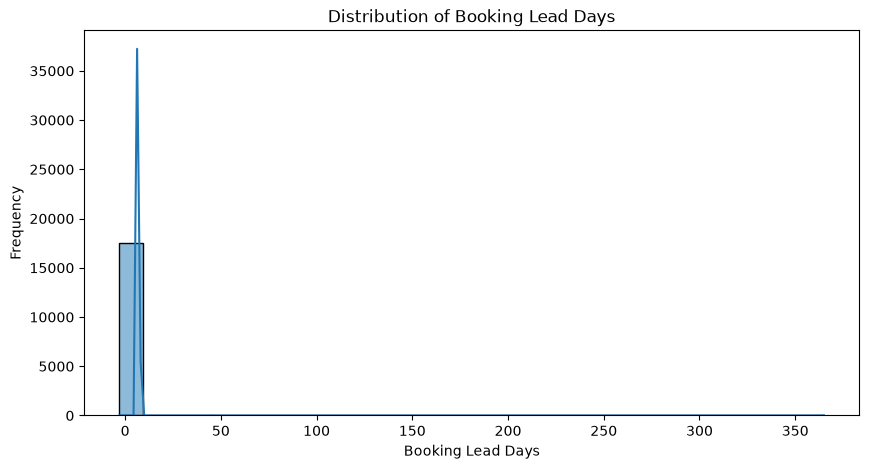

In [24]:
plt.figure(figsize=(10, 5))

sns.histplot(df['booking_lead_days'], bins=30, kde=True)

plt.title("Distribution of Booking Lead Days")
plt.xlabel("Booking Lead Days")
plt.ylabel("Frequency")

plt.show()

In [25]:
df.loc[df['booking_lead_days'] < 0, 'booking_lead_days'] = np.nan

In [26]:
df['booking_lead_days'].value_counts(dropna=False).sort_index()

booking_lead_days
0.0          1
7.0      17515
45.0         1
120.0        1
365.0        1
NaN          1
Name: count, dtype: int64

In [27]:
col = 'booked_seats_7d_before'

Q1 = df[col].quantile(0.25)
Q3 = df[col].quantile(0.75)

IQR = Q3 - Q1

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

Q1: 23.0
Q3: 36.0
IQR: 13.0


In [28]:
lower_limit = Q1 - (1.5 * IQR)
upper_limit = Q3 + (1.5 * IQR)

print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

Lower Limit: 3.5
Upper Limit: 55.5


In [29]:
outliers = df[
    (df[col] < lower_limit) |
    (df[col] > upper_limit)
]

outliers[['trip_id', 'route_id', 'bus_capacity', col]]

,trip_id,route_id,bus_capacity,booked_seats_7d_before
331,R001_20251128_0600,R001,50,90.0
515,R001_20250531_0800,R001,50,93.0
1600,R002_20250521_0600,R002,50,142.0
4206,R003_20250711_1800,R003,40,141.0
4895,R004_20250531_0800,R004,55,89.0
5577,R004_20250413_1800,R004,55,114.0
5652,R004_20250627_1800,R004,55,105.0
10094,R007_20250828_1800,R007,45,137.0
12749,R009_20251206_1400,R009,40,2.0


In [30]:
invalid_bookings = df[
    df['booked_seats_7d_before'] > df['bus_capacity']
]

invalid_bookings[
    ['trip_id', 'route_id', 'bus_capacity', 'booked_seats_7d_before']
]

,trip_id,route_id,bus_capacity,booked_seats_7d_before
331,R001_20251128_0600,R001,50,90.0
515,R001_20250531_0800,R001,50,93.0
1600,R002_20250521_0600,R002,50,142.0
4206,R003_20250711_1800,R003,40,141.0
4895,R004_20250531_0800,R004,55,89.0
5577,R004_20250413_1800,R004,55,114.0
5652,R004_20250627_1800,R004,55,105.0
10094,R007_20250828_1800,R007,45,137.0


In [31]:
print("Invalid bookings:", len(invalid_bookings))

Invalid bookings: 8


In [32]:


invalid_bookings = df['booked_seats_7d_before'] > df['bus_capacity']



df.loc[invalid_bookings, 'booked_seats_7d_before'] = np.nan

In [33]:
print(
    "Missing booking values:",
    df['booked_seats_7d_before'].isnull().sum()
)

Missing booking values: 218


In [34]:
col = 'weather_forecast_temp_c'

Q1 = df[col].quantile(0.25)
Q3 = df[col].quantile(0.75)

IQR = Q3 - Q1

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

Q1: 18.9
Q3: 27.5
IQR: 8.600000000000001


In [35]:
lower_limit = Q1 - (1.5 * IQR)
upper_limit = Q3 + (1.5 * IQR)

print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

Lower Limit: 5.9999999999999964
Upper Limit: 40.400000000000006


In [36]:
outliers = df[
    (df[col] < lower_limit) |
    (df[col] > upper_limit)
]

outliers[['trip_id', 'route_id', col]]

,trip_id,route_id,weather_forecast_temp_c
133,R001_20250514_0600,R001,41.3
457,R001_20250403_0800,R001,42.4
469,R001_20250415_0800,R001,41.2
783,R001_20250223_1400,R001,3.8
837,R001_20250418_1400,R001,40.7
...,...,...,...
15817,R011_20250503_1800,R011,41.5
16411,R012_20251218_0600,R012,5.2
17110,R012_20251117_1400,R012,4.3
17204,R012_20250219_1800,R012,5.6


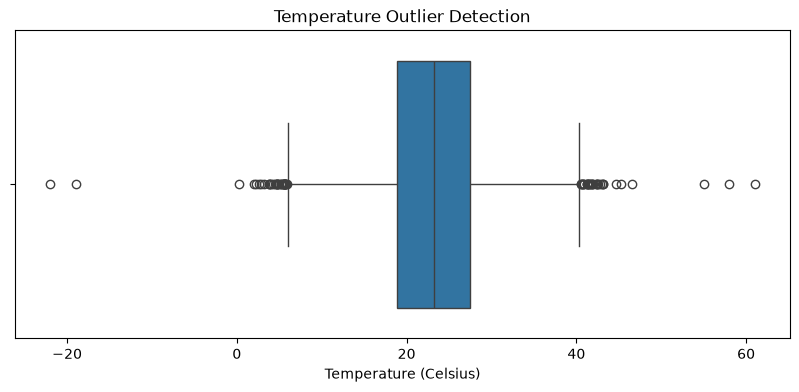

In [37]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=df[col])

plt.title("Temperature Outlier Detection")
plt.xlabel("Temperature (Celsius)")

plt.show()

In [38]:
print("Minimum Temperature:", df[col].min())

print("Maximum Temperature:", df[col].max())

Minimum Temperature: -22.0
Maximum Temperature: 61.0


In [39]:
df[
    (df[col] < 0) |
    (df[col] > 45)
][['trip_id', 'route_id', 'departure_date', col]]

,trip_id,route_id,departure_date,weather_forecast_temp_c
7791,R006_20250507_0800,R006,2025-05-07,46.5
9022,R007_20250920_0600,R007,2025-09-20,58.0
9289,R007_20250614_0800,R007,2025-06-14,61.0
11473,R008_20250608_1800,R008,2025-06-08,45.3
12219,R009_20250624_0800,R009,2025-06-24,-22.0
12246,R009_20250721_0800,R009,2025-07-21,55.0
17430,R012_20251003_1800,R012,2025-10-03,-19.0


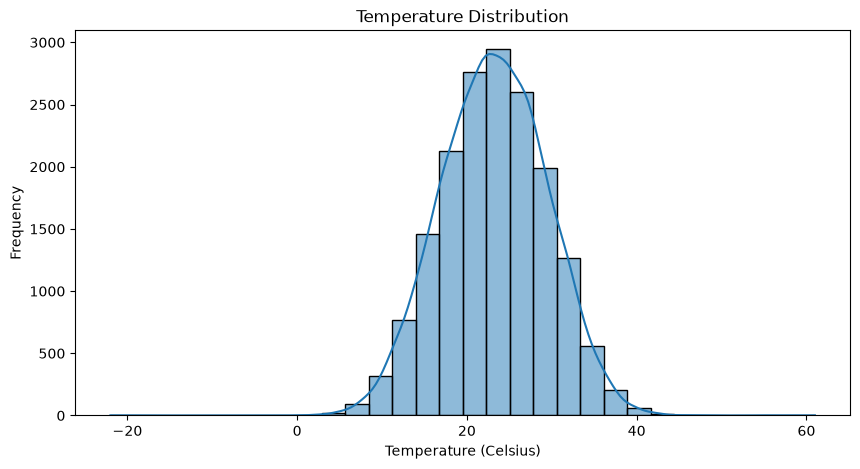

In [40]:
plt.figure(figsize=(10, 5))

sns.histplot(df[col], bins=30, kde=True)

plt.title("Temperature Distribution")
plt.xlabel("Temperature (Celsius)")
plt.ylabel("Frequency")

plt.show()

In [41]:
df.loc[
    (df['weather_forecast_temp_c'] < -10) |
    (df['weather_forecast_temp_c'] > 50),
    'weather_forecast_temp_c'
] = np.nan

In [42]:
print(
    "Missing temperature values:",
    df['weather_forecast_temp_c'].isnull().sum()
)

Missing temperature values: 319


In [43]:
col = 'weather_forecast_rain_probability'

Q1 = df[col].quantile(0.25)
Q3 = df[col].quantile(0.75)

IQR = Q3 - Q1

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

Q1: 0.19
Q3: 0.43
IQR: 0.24


In [44]:
lower_limit = Q1 - (1.5 * IQR)
upper_limit = Q3 + (1.5 * IQR)

print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

Lower Limit: -0.16999999999999998
Upper Limit: 0.79


In [45]:
outliers = df[
    (df[col] < lower_limit) |
    (df[col] > upper_limit)
]

outliers[['trip_id', 'route_id', col]]

,trip_id,route_id,weather_forecast_rain_probability
588,R001_20250812_0800,R001,0.81
591,R001_20250815_0800,R001,0.81
978,R001_20250906_1400,R001,0.86
979,R001_20250907_1400,R001,0.91
988,R001_20250916_1400,R001,0.94
...,...,...,...
15933,R011_20250827_1800,R011,0.80
16025,R011_20251127_1800,R011,0.86
16286,R012_20250815_0600,R012,0.83
17217,R012_20250304_1800,R012,0.83


In [46]:
print("Minimum:", df[col].min())
print("Maximum:", df[col].max())

Minimum: 0.0
Maximum: 0.99


In [47]:
invalid_rain = df[
    (df['weather_forecast_rain_probability'] < 0) |
    (df['weather_forecast_rain_probability'] > 1)
]

invalid_rain

,trip_id,route_id,source,destination,departure_date,departure_time,day_of_week,month,season,bus_capacity,booking_lead_days,booked_seats_7d_before,historical_route_time_avg_28d,historical_same_weekday_avg_4w,weather_forecast_temp_c,weather_forecast_rain_probability,passenger_count


In [48]:
col = 'passenger_count'

Q1 = df[col].quantile(0.25)
Q3 = df[col].quantile(0.75)

IQR = Q3 - Q1

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

Q1: 32.0
Q3: 50.0
IQR: 18.0


In [49]:
Q1 = df['passenger_count'].quantile(0.25)
Q3 = df['passenger_count'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df['passenger_count'] < lower_limit) |
    (df['passenger_count'] > upper_limit)
]

outliers[['trip_id', 'route_id', 'bus_capacity', 'passenger_count']]

,trip_id,route_id,bus_capacity,passenger_count
112,R001_20250423_0600,R001,50,96.0
11293,R008_20251210_1400,R008,50,105.0
14216,R010_20251213_1400,R010,55,88.0
15630,R011_20251028_1400,R011,50,120.0


In [50]:
invalid_passengers = df[
    df['passenger_count'] > df['bus_capacity']
]

invalid_passengers[
    ['trip_id', 'route_id', 'bus_capacity', 'passenger_count']
]

,trip_id,route_id,bus_capacity,passenger_count
112,R001_20250423_0600,R001,50,96.0
11293,R008_20251210_1400,R008,50,105.0
14216,R010_20251213_1400,R010,55,88.0
15630,R011_20251028_1400,R011,50,120.0


In [51]:
df['passenger_count'].isnull().sum()

np.int64(17)

In [52]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
month,17520.0,6.526027,3.447950,1.0,4.00,7.0,10.00,12.00
bus_capacity,17520.0,47.500000,5.204314,40.0,43.75,50.0,50.00,55.00
booking_lead_days,17519.0,7.028655,2.851218,0.0,7.00,7.0,7.00,365.00
booked_seats_7d_before,17302.0,29.366374,8.653729,2.0,23.00,29.0,36.00,55.00
historical_route_time_avg_28d,16594.0,39.495818,8.865539,20.2,31.80,40.6,47.60,54.90
historical_same_weekday_avg_4w,16093.0,39.478456,9.260559,13.0,31.80,40.2,48.00,55.00
weather_forecast_temp_c,17201.0,23.199047,6.205107,0.3,18.90,23.2,27.50,46.50
weather_forecast_rain_probability,17135.0,0.316769,0.169039,0.0,0.19,0.3,0.43,0.99
passenger_count,17503.0,39.531109,10.103263,5.0,32.00,40.0,50.00,120.00


In [53]:
categorical_cols = df.select_dtypes(include=['object']).columns

for col in categorical_cols:
    print("\nColumn:", col)
    print(df[col].value_counts(dropna=False))


Column: trip_id
trip_id
R001_20250101_0600    1
R001_20250102_0600    1
R001_20250103_0600    1
R001_20250104_0600    1
R001_20250105_0600    1
                     ..
R012_20251227_1800    1
R012_20251228_1800    1
R012_20251229_1800    1
R012_20251230_1800    1
R012_20251231_1800    1
Name: count, Length: 17520, dtype: int64

Column: route_id
route_id
R001    1460
R002    1460
R003    1460
R004    1460
R005    1460
R006    1460
R007    1460
R008    1460
R009    1460
R010    1460
R011    1460
R012    1460
Name: count, dtype: int64

Column: source
source
Delhi         4380
Chandigarh    1460
Jaipur        1460
Mumbai        1460
Bengaluru     1460
Hyderabad     1460
Kolkata       1460
Chennai       1460
Ahmedabad     1460
Patna         1460
Name: count, dtype: int64

Column: destination
destination
Chandigarh     1460
Jaipur         1460
Ludhiana       1460
Lucknow        1460
Udaipur        1460
Pune           1460
Mysuru         1460
Vijayawada     1460
Durgapur       1460
Bengaluru

C:\Users\hp\AppData\Local\Temp\ipykernel_14280\939155281.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include=['object']).columns


In [54]:
print("Duplicate rows:", df.duplicated().sum())

print("Duplicate trip IDs:", df['trip_id'].duplicated().sum())

Duplicate rows: 0
Duplicate trip IDs: 0


In [55]:
categorical_cols = df.select_dtypes(include=['object']).columns

for col in categorical_cols:
    print(col, ":", df[col].isnull().sum())

trip_id : 0
route_id : 0
source : 0
destination : 0
departure_date : 0
departure_time : 35
day_of_week : 0
season : 70


C:\Users\hp\AppData\Local\Temp\ipykernel_14280\3669327455.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include=['object']).columns


In [56]:
missing_time = df[df['departure_time'].isnull()]

missing_time[
    ['trip_id', 'route_id', 'source', 'destination',
     'departure_date', 'departure_time']
]

,trip_id,route_id,source,destination,departure_date,departure_time
1424,R001_20251126_1800,R001,Delhi,Chandigarh,2025-11-26,NaN
1509,R002_20250219_0600,R002,Delhi,Jaipur,2025-02-19,NaN
1790,R002_20251127_0600,R002,Delhi,Jaipur,2025-11-27,NaN
1941,R002_20250427_0800,R002,Delhi,Jaipur,2025-04-27,NaN
2303,R002_20250424_1400,R002,Delhi,Jaipur,2025-04-24,NaN
2397,R002_20250727_1400,R002,Delhi,Jaipur,2025-07-27,NaN
2818,R002_20250921_1800,R002,Delhi,Jaipur,2025-09-21,NaN
5554,R004_20250321_1800,R004,Delhi,Lucknow,2025-03-21,NaN
5816,R004_20251208_1800,R004,Delhi,Lucknow,2025-12-08,NaN
5860,R005_20250121_0600,R005,Jaipur,Udaipur,2025-01-21,NaN


In [57]:
missing_time = df[df['departure_time'].isnull()].copy()

missing_time['time_from_trip_id'] = (
    missing_time['trip_id'].str.rsplit('_', n=1).str[-1]
)

print(missing_time['time_from_trip_id'].value_counts(dropna=False))

time_from_trip_id
0800    10
1800     9
0600     8
1400     8
Name: count, dtype: int64


In [58]:
valid_times = ['0600', '0800', '1400', '1800']

invalid_times = missing_time[
    ~missing_time['time_from_trip_id'].isin(valid_times)
]

print("Invalid time codes:", len(invalid_times))

Invalid time codes: 0


In [59]:
df.loc[df['departure_time'].isnull(), 'departure_time'] = (
    df.loc[df['departure_time'].isnull(), 'trip_id']
    .str.rsplit('_', n=1)
    .str[-1]
)

In [60]:
print("Missing departure times:", df['departure_time'].isnull().sum())

print(df['departure_time'].value_counts())

Missing departure times: 0
departure_time
06:00    4372
14:00    4372
18:00    4371
08:00    4370
0800       10
1800        9
0600        8
1400        8
Name: count, dtype: int64


In [61]:
df['departure_time'] = df['departure_time'].astype(str).str.replace(
    r'^(\d{2})(\d{2})$', r'\1:\2', regex=True
)

print(df['departure_time'].value_counts())

departure_time
06:00    4380
08:00    4380
14:00    4380
18:00    4380
Name: count, dtype: int64


In [62]:
missing_season = df[df['season'].isnull()]

missing_season[
    ['trip_id', 'departure_date', 'month', 'season']
]

,trip_id,departure_date,month,season
281,R001_20251009_0600,2025-10-09,10,NaN
855,R001_20250506_1400,2025-05-06,5,NaN
987,R001_20250915_1400,2025-09-15,9,NaN
1041,R001_20251108_1400,2025-11-08,11,NaN
1087,R001_20251224_1400,2025-12-24,12,NaN
...,...,...,...,...
16328,R012_20250926_0600,2025-09-26,9,NaN
16394,R012_20251201_0600,2025-12-01,12,NaN
16725,R012_20251028_0800,2025-10-28,10,NaN
16793,R012_20250104_1400,2025-01-04,1,NaN


In [63]:
season_mapping_check = df.groupby('month')['season'].value_counts()

print(season_mapping_check)

month  season 
1      Winter     1480
2      Winter     1338
3      Summer     1481
4      Summer     1434
5      Summer     1482
6      Summer     1439
7      Monsoon    1484
8      Monsoon    1480
9      Monsoon    1434
10     Winter     1483
11     Winter     1434
12     Winter     1481
Name: count, dtype: int64


In [64]:
season_mapping = {
    1: 'Winter',
    2: 'Winter',
    3: 'Summer',
    4: 'Summer',
    5: 'Summer',
    6: 'Summer',
    7: 'Monsoon',
    8: 'Monsoon',
    9: 'Monsoon',
    10: 'Winter',
    11: 'Winter',
    12: 'Winter'
}

df['season'] = df['season'].fillna(
    df['month'].map(season_mapping)
)

In [65]:
print("Missing season values:", df['season'].isnull().sum())

print(df['season'].value_counts())

Missing season values: 0
season
Winter     7248
Summer     5856
Monsoon    4416
Name: count, dtype: int64


In [66]:
missing_summary = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': (df.isnull().sum() / len(df)) * 100
})

missing_summary = missing_summary[
    missing_summary['Missing_Count'] > 0
].sort_values(by='Missing_Count', ascending=False)

missing_summary

,Missing_Count,Missing_Percentage
historical_same_weekday_avg_4w,1427,8.144977
historical_route_time_avg_28d,926,5.285388
weather_forecast_rain_probability,385,2.197489
weather_forecast_temp_c,319,1.820776
booked_seats_7d_before,218,1.244292
passenger_count,17,0.097032
booking_lead_days,1,0.005708


In [67]:
print("Date data type:", df['departure_date'].dtype)

print("Start date:", df['departure_date'].min())

print("End date:", df['departure_date'].max())

print("Already sorted:", df['departure_date'].is_monotonic_increasing)

Date data type: str
Start date: 2025-01-01
End date: 2025-12-31
Already sorted: False


In [68]:
df['departure_date'] = pd.to_datetime(df['departure_date'])

print("Date data type:", df['departure_date'].dtype)
print("Start date:", df['departure_date'].min())
print("End date:", df['departure_date'].max())

Date data type: datetime64[us]
Start date: 2025-01-01 00:00:00
End date: 2025-12-31 00:00:00


In [69]:
df = df.sort_values(
    by=['departure_date', 'departure_time', 'route_id']
).reset_index(drop=True)

print("Already sorted:", df['departure_date'].is_monotonic_increasing)

print(df[['trip_id', 'departure_date', 'departure_time']].head())

Already sorted: True
              trip_id departure_date departure_time
0  R001_20250101_0600     2025-01-01          06:00
1  R002_20250101_0600     2025-01-01          06:00
2  R003_20250101_0600     2025-01-01          06:00
3  R004_20250101_0600     2025-01-01          06:00
4  R005_20250101_0600     2025-01-01          06:00


In [70]:
split_index = int(len(df) * 0.80)

train_df = df.iloc[:split_index].copy()
test_df = df.iloc[split_index:].copy()

print("Training records:", len(train_df))
print("Testing records:", len(test_df))

print("\nTraining period:")
print(train_df['departure_date'].min(), "to",
      train_df['departure_date'].max())

print("\nTesting period:")
print(test_df['departure_date'].min(), "to",
      test_df['departure_date'].max())

Training records: 14016
Testing records: 3504

Training period:
2025-01-01 00:00:00 to 2025-10-19 00:00:00

Testing period:
2025-10-20 00:00:00 to 2025-12-31 00:00:00


In [71]:
for name, data in [('Training', train_df), ('Testing', test_df)]:

    print("\n", name, "Dataset")

    missing = data.isnull().sum()

    print(missing[missing > 0])


 Training Dataset
booking_lead_days                       1
booked_seats_7d_before                178
historical_route_time_avg_28d         865
historical_same_weekday_avg_4w       1339
weather_forecast_temp_c               273
weather_forecast_rain_probability     296
passenger_count                        16
dtype: int64

 Testing Dataset
booked_seats_7d_before               40
historical_route_time_avg_28d        61
historical_same_weekday_avg_4w       88
weather_forecast_temp_c              46
weather_forecast_rain_probability    89
passenger_count                       1
dtype: int64


In [72]:
print("Training booking lead days:")
print(train_df['booking_lead_days'].value_counts(dropna=False).sort_index())

print("\nTesting booking lead days:")
print(test_df['booking_lead_days'].value_counts(dropna=False).sort_index())

Training booking lead days:
booking_lead_days
7.0      14012
45.0         1
120.0        1
365.0        1
NaN          1
Name: count, dtype: int64

Testing booking lead days:
booking_lead_days
0.0       1
7.0    3503
Name: count, dtype: int64


In [73]:
print("Training: Missing historical route average")
print(
    train_df.loc[
        train_df['historical_route_time_avg_28d'].isnull(),
        'departure_date'
    ].agg(['min', 'max'])
)

print("\nTraining: Missing same weekday average")
print(
    train_df.loc[
        train_df['historical_same_weekday_avg_4w'].isnull(),
        'departure_date'
    ].agg(['min', 'max'])
)

Training: Missing historical route average
min   2025-01-01
max   2025-10-17
Name: departure_date, dtype: datetime64[us]

Training: Missing same weekday average
min   2025-01-01
max   2025-10-18
Name: departure_date, dtype: datetime64[us]


In [76]:
print("Missing historical route average by route:")

print(
    train_df.groupby('route_id')
    ['historical_route_time_avg_28d']
    .apply(lambda x: x.isnull().sum())
)

print("\nMissing same weekday average by route:")

print(
    train_df.groupby('route_id')
    ['historical_same_weekday_avg_4w']
    .apply(lambda x: x.isnull().sum())
)

Missing historical route average by route:
route_id
R001    73
R002    73
R003    72
R004    73
R005    71
R006    67
R007    75
R008    69
R009    71
R010    73
R011    68
R012    80
Name: historical_route_time_avg_28d, dtype: int64

Missing same weekday average by route:
route_id
R001    107
R002    116
R003    112
R004    116
R005    114
R006    109
R007    117
R008    111
R009    119
R010    110
R011    104
R012    104
Name: historical_same_weekday_avg_4w, dtype: int64


In [77]:
print("Historical route average missing by month:")

print(
    train_df.groupby(train_df['departure_date'].dt.month)
    ['historical_route_time_avg_28d']
    .apply(lambda x: x.isnull().sum())
)

print("\nSame weekday average missing by month:")

print(
    train_df.groupby(train_df['departure_date'].dt.month)
    ['historical_same_weekday_avg_4w']
    .apply(lambda x: x.isnull().sum())
)

Historical route average missing by month:
departure_date
1     692
2      28
3      15
4      21
5      20
6      18
7      19
8      20
9      24
10      8
Name: historical_route_time_avg_28d, dtype: int64

Same weekday average missing by month:
departure_date
1     1017
2       30
3       43
4       40
5       46
6       36
7       36
8       39
9       35
10      17
Name: historical_same_weekday_avg_4w, dtype: int64


In [78]:
print("Missing route average dates:")

print(
    train_df.loc[
        train_df['historical_route_time_avg_28d'].isnull(),
        'departure_date'
    ].dt.strftime('%Y-%m-%d').value_counts().sort_index()
)

Missing route average dates:
departure_date
2025-01-01    48
2025-01-02    48
2025-01-03    48
2025-01-04    48
2025-01-05    48
              ..
2025-10-08     1
2025-10-09     1
2025-10-14     1
2025-10-16     1
2025-10-17     1
Name: count, Length: 150, dtype: int64


In [79]:
print(
    df[
        [
            'departure_date',
            'route_id',
            'departure_time',
            'passenger_count',
            'historical_route_time_avg_28d',
            'historical_same_weekday_avg_4w'
        ]
    ].head(20)
)

   departure_date route_id departure_time  passenger_count  \
0      2025-01-01     R001          06:00             49.0   
1      2025-01-01     R002          06:00             41.0   
2      2025-01-01     R003          06:00             28.0   
3      2025-01-01     R004          06:00             41.0   
4      2025-01-01     R005          06:00             32.0   
5      2025-01-01     R006          06:00             50.0   
6      2025-01-01     R007          06:00             25.0   
7      2025-01-01     R008          06:00             42.0   
8      2025-01-01     R009          06:00             23.0   
9      2025-01-01     R010          06:00             40.0   
10     2025-01-01     R011          06:00             37.0   
11     2025-01-01     R012          06:00             29.0   
12     2025-01-01     R001          08:00             47.0   
13     2025-01-01     R002          08:00             50.0   
14     2025-01-01     R003          08:00             29.0   
15     2